In [4]:
import os
import json
import random
from pathlib import Path
from collections import Counter

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

# --- Reproducibility ---
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.cuda.manual_seed_all(SEED)

# --- Project paths (notebook lives in dl-project/notebooks/) ---
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

DATA_DIR   = PROJECT_ROOT / "data" / "intel"
TRAIN_DIR  = DATA_DIR / "seg_train"
TEST_DIR   = DATA_DIR / "seg_test"
PRED_DIR   = DATA_DIR / "seg_pred"
MODELS_DIR = PROJECT_ROOT / "models"
OUTPUT_DIR = PROJECT_ROOT / "outputs"

MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# --- Global hyperparameters shared across the whole project ---
IMG_SIZE      = 224
BATCH_SIZE    = 64
VAL_RATIO     = 0.15
NUM_WORKERS   = 0          # Windows + Jupyter: keep 0 to avoid multiprocessing issues
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PROJECT_ROOT :", PROJECT_ROOT)
print("TRAIN_DIR    :", TRAIN_DIR, "| exists:", TRAIN_DIR.exists())
print("TEST_DIR     :", TEST_DIR,  "| exists:", TEST_DIR.exists())
print("PRED_DIR     :", PRED_DIR,  "| exists:", PRED_DIR.exists())
print("DEVICE       :", DEVICE)


PROJECT_ROOT : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project
TRAIN_DIR    : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_train | exists: True
TEST_DIR     : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_test | exists: True
PRED_DIR     : c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_pred | exists: True
DEVICE       : cuda


In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

def resolve_split_dir(path: Path) -> Path:
    """اگر پوشه فقط یک زیرپوشه همنام داشته باشد (seg_train/seg_train)، لایه اضافه را رد می‌کند."""
    subdirs = [d for d in path.iterdir() if d.is_dir()]
    if len(subdirs) == 1 and subdirs[0].name == path.name:
        return subdirs[0]
    return path

TRAIN_DIR = resolve_split_dir(TRAIN_DIR)
TEST_DIR  = resolve_split_dir(TEST_DIR)

CLASS_NAMES = sorted(d.name for d in TRAIN_DIR.iterdir() if d.is_dir())
NUM_CLASSES = len(CLASS_NAMES)

def count_images(root: Path) -> dict:
    return {
        cls: sum(1 for f in (root / cls).iterdir() if f.suffix.lower() in IMG_EXTS)
        for cls in CLASS_NAMES
    }

train_counts = count_images(TRAIN_DIR)
test_counts  = count_images(TEST_DIR)
pred_count   = sum(1 for f in PRED_DIR.iterdir() if f.suffix.lower() in IMG_EXTS)

print("TRAIN_DIR (resolved):", TRAIN_DIR)
print("TEST_DIR  (resolved):", TEST_DIR)
print("CLASS_NAMES:", CLASS_NAMES, "| NUM_CLASSES:", NUM_CLASSES, "\n")

total_tr, total_te = sum(train_counts.values()), sum(test_counts.values())
print(f"{'class':<12}{'train':>8}{'train %':>10}{'test':>8}{'test %':>10}")
print("-" * 48)
for cls in CLASS_NAMES:
    tr, te = train_counts[cls], test_counts[cls]
    print(f"{cls:<12}{tr:>8}{tr/total_tr*100:>9.2f}%{te:>8}{te/total_te*100:>9.2f}%")
print("-" * 48)
print(f"{'TOTAL':<12}{total_tr:>8}{'':>10}{total_te:>8}")
print(f"\nseg_pred (unlabeled): {pred_count} images")


TRAIN_DIR (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_train\seg_train
TEST_DIR  (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_test\seg_test
CLASS_NAMES: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street'] | NUM_CLASSES: 6 

class          train   train %    test    test %
------------------------------------------------
buildings       2191    15.61%     437    14.57%
forest          2271    16.18%     474    15.80%
glacier         2404    17.13%     553    18.43%
mountain        2512    17.90%     525    17.50%
sea             2274    16.20%     510    17.00%
street          2382    16.97%     501    16.70%
------------------------------------------------
TOTAL          14034              3000

seg_pred (unlabeled): 0 images


In [ ]:
PRED_DIR = resolve_split_dir(PRED_DIR)
pred_files = [f for f in PRED_DIR.rglob("*") if f.suffix.lower() in IMG_EXTS]
print("PRED_DIR (resolved):", PRED_DIR)
print("seg_pred images:", len(pred_files), "\n")

# نمونه‌گیری تصادفی برای بررسی ابعاد و مود رنگی
random.seed(SEED)
sample = []
for cls in CLASS_NAMES:
    files = [f for f in (TRAIN_DIR / cls).iterdir() if f.suffix.lower() in IMG_EXTS]
    sample += random.sample(files, min(200, len(files)))

sizes, modes, corrupt = Counter(), Counter(), []
for f in sample:
    try:
        with Image.open(f) as im:
            im.verify()
        with Image.open(f) as im:
            sizes[im.size] += 1
            modes[im.mode] += 1
    except Exception as e:
        corrupt.append((f.name, type(e).__name__))

print(f"بررسی‌شده: {len(sample)} تصویر | خراب: {len(corrupt)}")
if corrupt:
    print("نمونه فایل‌های خراب:", corrupt[:5])

print("\nپرتکرارترین ابعاد:")
for size, n in sizes.most_common(5):
    print(f"  {size[0]}x{size[1]:<6} -> {n:>4} ({n/len(sample)*100:.1f}%)")
print(f"  تعداد ابعاد یکتا: {len(sizes)}")

print("\nمود رنگی:", dict(modes))


PRED_DIR (resolved): c:\Users\ARTA PC\Desktop\Deep Learning\dl-project\data\intel\seg_pred\seg_pred
seg_pred images: 7301 

بررسی‌شده: 1200 تصویر | خراب: 0

پرتکرارترین ابعاد:
  150x150    -> 1198 (99.8%)
  150x134    ->    1 (0.1%)
  150x123    ->    1 (0.1%)
  تعداد ابعاد یکتا: 3

مود رنگی: {'RGB': 1200}


In [ ]:
IMG_SIZE   = 224
BATCH_SIZE = 32
VAL_RATIO  = 0.15
MEAN = [0.485, 0.456, 0.406]   # ImageNet statistics
STD  = [0.229, 0.224, 0.225]

# Augmentation only on the training branch
train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.2),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Deterministic pipeline for validation and test
eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(MEAN, STD),
])

# Two views of the same folder, different transforms
full_train = datasets.ImageFolder(TRAIN_DIR, transform=train_tf)
full_eval  = datasets.ImageFolder(TRAIN_DIR, transform=eval_tf)
test_ds    = datasets.ImageFolder(TEST_DIR,  transform=eval_tf)

assert full_train.classes == test_ds.classes, "Class order mismatch between train and test"
CLASS_NAMES = full_train.classes
NUM_CLASSES = len(CLASS_NAMES)

# Reproducible index split
g = torch.Generator().manual_seed(SEED)
perm     = torch.randperm(len(full_train), generator=g).tolist()
n_val    = int(len(perm) * VAL_RATIO)
val_idx  = perm[:n_val]
train_idx = perm[n_val:]

train_ds = Subset(full_train, train_idx)   # augmented
val_ds   = Subset(full_eval,  val_idx)     # clean

common = dict(num_workers=0, pin_memory=True)   # num_workers=0 -> Windows-safe
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  drop_last=True,  **common)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, **common)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, **common)

print(f"classes ({NUM_CLASSES}): {CLASS_NAMES}")
print(f"train: {len(train_ds):>6} sample | {len(train_loader):>4} batch")
print(f"val:   {len(val_ds):>6} sample | {len(val_loader):>4} batch")
print(f"test:  {len(test_ds):>6} sample | {len(test_loader):>4} batch")

# Shape and value-range sanity check on one batch
xb, yb = next(iter(train_loader))
print(f"\nbatch x: {tuple(xb.shape)} {xb.dtype} | range [{xb.min():.2f}, {xb.max():.2f}]")
print(f"batch y: {tuple(yb.shape)} | labels {yb[:8].tolist()}")


classes (6): ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train:  11929 sample |  372 batch
val:     2105 sample |   66 batch
test:    3000 sample |   94 batch

batch x: (32, 3, 224, 224) torch.float32 | range [-2.12, 2.64]
batch y: (32,) | labels [5, 4, 2, 2, 4, 5, 1, 4]


انتقال یادگیری


In [ ]:
# ====== Transfer Learning with ResNet18 ======

import torch.nn as nn
from torchvision import models
from torch.utils.data import random_split

# 1. Load pretrained ResNet18
model_tl = models.resnet18(weights='IMAGENET1K_V1')

# 2. Replace final layer for 6 classes
model_tl.fc = nn.Linear(model_tl.fc.in_features, NUM_CLASSES)
model_tl = model_tl.to(DEVICE)

# 3. Prepare datasets for transfer learning
# Use same augmentation for training
train_tf_tl = transforms.Compose([
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                       std=[0.229, 0.224, 0.225])
])

eval_tf_tl = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                       std=[0.229, 0.224, 0.225])
])

# Load full training set
full_train_ds_tl = datasets.ImageFolder(TRAIN_DIR)

# Split into train and val (same ratio as before: 80-20)
train_size_tl = int(0.8 * len(full_train_ds_tl))
val_size_tl = len(full_train_ds_tl) - train_size_tl

train_ds_tl, val_ds_tmp = random_split(
    full_train_ds_tl,
    [train_size_tl, val_size_tl],
    generator=torch.Generator().manual_seed(SEED)
)

# Wrap validation subset with eval transforms
class TransformSubset(torch.utils.data.Dataset):
    def __init__(self, subset, transform=None):
        self.subset = subset
        self.transform = transform

    def __getitem__(self, idx):
        x, y = self.subset[idx]
        if self.transform:
            x = self.transform(x)
        return x, y

    def __len__(self):
        return len(self.subset)

train_ds_tl = TransformSubset(train_ds_tl, train_tf_tl)
val_ds_tl = TransformSubset(val_ds_tmp, eval_tf_tl)
test_ds_tl = datasets.ImageFolder(TEST_DIR, transform=eval_tf_tl)

# Create dataloaders
train_loader_tl = DataLoader(train_ds_tl, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True)
val_loader_tl = DataLoader(val_ds_tl, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)
test_loader_tl = DataLoader(test_ds_tl, batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print(f'classes      : {full_train_ds_tl.classes}')
print(f'train samples: {len(train_ds_tl)}')
print(f'val samples  : {len(val_ds_tl)}')
print(f'test samples : {len(test_ds_tl)}')
print(f'params total : {sum(p.numel() for p in model_tl.parameters())/1e6:.2f}M')


classes      : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
train samples: 11227
val samples  : 2807
test samples : 3000
params total : 11.18M


مرحله اول: فریز کردن بدنه + آموزش فقط لایه نهایی (5 ایپاک، LR=0.001)

In [ ]:
# ====== Freeze backbone, train only FC ======
import torch.optim as optim
import copy

# Freeze all layers except the final fc
for param in model_tl.parameters():
    param.requires_grad = False
for param in model_tl.fc.parameters():
    param.requires_grad = True

# Optimizer and scheduler for phase 1
optimizer_tl_p1 = optim.Adam(model_tl.fc.parameters(), lr=0.001)
scheduler_tl_p1 = optim.lr_scheduler.CosineAnnealingLR(optimizer_tl_p1, T_max=5)

# Define loss function
criterion = nn.CrossEntropyLoss()

# Train phase 1
best_val_acc_p1 = 0.0
best_model_p1 = None
history_tl_p1 = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': [], 'lr': []}

print("Phase 1: Training only FC layer (5 epochs)")
for epoch in range(5):
    # Train
    model_tl.train()
    train_loss, train_correct, train_total = 0.0, 0, 0
    
    for inputs, labels in train_loader_tl:
        inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
        
        optimizer_tl_p1.zero_grad()
        outputs = model_tl(inputs)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_tl_p1.step()
        
        train_loss += loss.item() * inputs.size(0)
        _, preds = torch.max(outputs, 1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)
    
    train_loss = train_loss / train_total
    train_acc = 100.0 * train_correct / train_total
    
    # Validation
    model_tl.eval()
    val_loss, val_correct, val_total = 0.0, 0, 0
    
    with torch.no_grad():
        for inputs, labels in val_loader_tl:
            inputs, labels = inputs.to(DEVICE), labels.to(DEVICE)
            outputs = model_tl(inputs)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * inputs.size(0)
            _, preds = torch.max(outputs, 1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)
    
    val_loss = val_loss / val_total
    val_acc = 100.0 * val_correct / val_total
    
    # Save best model
    if val_acc > best_val_acc_p1:
        best_val_acc_p1 = val_acc
        best_model_p1 = copy.deepcopy(model_tl.state_dict())
    
    # Record history
    history_tl_p1['train_loss'].append(train_loss)
    history_tl_p1['train_acc'].append(train_acc)
    history_tl_p1['val_loss'].append(val_loss)
    history_tl_p1['val_acc'].append(val_acc)
    history_tl_p1['lr'].append(optimizer_tl_p1.param_groups[0]['lr'])
    
    scheduler_tl_p1.step()
    
    print(f'Epoch {epoch+1}/5 - Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%, '
          f'Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%')

print(f'\nPhase 1 Best Val Acc: {best_val_acc_p1:.2f}%')

# Load best model from phase 1
model_tl.load_state_dict(best_model_p1)


Phase 1: Training only FC layer (5 epochs)
Epoch 1/5 - Train Loss: 0.6443, Train Acc: 77.65%, Val Loss: 0.3042, Val Acc: 89.63%
Epoch 2/5 - Train Loss: 0.4535, Train Acc: 83.27%, Val Loss: 0.2718, Val Acc: 90.74%
Epoch 3/5 - Train Loss: 0.4363, Train Acc: 84.28%, Val Loss: 0.2657, Val Acc: 90.84%
Epoch 4/5 - Train Loss: 0.4061, Train Acc: 84.86%, Val Loss: 0.2618, Val Acc: 90.92%
Epoch 5/5 - Train Loss: 0.4101, Train Acc: 84.96%, Val Loss: 0.2567, Val Acc: 90.81%

Phase 1 Best Val Acc: 90.92%


<All keys matched successfully>

مرحله دوم: Fine-tuning (آموزش لایه‌های عمیق‌تر)

In [10]:
def train_model(model, train_loader, val_loader, criterion, optimizer, scheduler, epochs, device):
    """
    تابع عمومی آموزش مدل با tracking دقت و loss
    """
    history = {
        'train_loss': [], 'train_acc': [],
        'val_loss': [], 'val_acc': [],
        'lr': []
    }
    
    for epoch in range(epochs):
        # ========== Training phase ==========
        model.train()
        running_loss, correct, total = 0.0, 0, 0
        
        for images, labels in train_loader:
            images, labels = images.to(device), labels.to(device)
            
            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            
            running_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            correct += (predicted == labels).sum().item()
            total += labels.size(0)
        
        train_loss = running_loss / total
        train_acc = 100 * correct / total
        
        # ========== Validation phase ==========
        model.eval()
        val_running_loss, val_correct, val_total = 0.0, 0, 0
        
        with torch.no_grad():
            for images, labels in val_loader:
                images, labels = images.to(device), labels.to(device)
                outputs = model(images)
                loss = criterion(outputs, labels)
                
                val_running_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                val_correct += (predicted == labels).sum().item()
                val_total += labels.size(0)
        
        val_loss = val_running_loss / val_total
        val_acc = 100 * val_correct / val_total
        
        # Update learning rate
        current_lr = optimizer.param_groups[0]['lr']
        scheduler.step()
        
        # Save history
        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)
        history['lr'].append(current_lr)
        
        print(f"Epoch {epoch+1}/{epochs} | "
              f"Train Loss: {train_loss:.4f}, Acc: {train_acc:.2f}% | "
              f"Val Loss: {val_loss:.4f}, Acc: {val_acc:.2f}% | "
              f"LR: {current_lr:.6f}")
    
    return history


In [ ]:
# ========== Fine-tune last residual block ==========
print("\nPhase 2: Fine-tuning layer4 + FC (10 epochs)")

# 1. Unfreeze layer4 (آخرین بلاک residual)
for param in model_tl.layer4.parameters():
    param.requires_grad = True

# 2. Optimizer با learning rate پایین‌تر
optimizer_ft = optim.AdamW([
    {'params': model_tl.layer4.parameters(), 'lr': 1e-4},  # layer4 با LR کم
    {'params': model_tl.fc.parameters(), 'lr': 5e-4}       # fc همچنان بالاتر
], weight_decay=1e-4)

# 3. Scheduler
scheduler_ft = optim.lr_scheduler.CosineAnnealingLR(
    optimizer_ft, T_max=10, eta_min=1e-6
)

# 4. Train
history_ft = train_model(
    model_tl, 
    train_loader_tl, 
    val_loader_tl, 
    criterion, 
    optimizer_ft, 
    scheduler_ft,
    epochs=10,
    device=device
)

# 5. ذخیره بهترین مدل مرحله ۲
best_model_path_ft = MODELS_DIR / "best_resnet18_finetuned.pth"
torch.save(model_tl.state_dict(), best_model_path_ft)
print(f"Phase 2 Best Val Acc: {max(history_ft['val_acc']):.2f}%")



Phase 2: Fine-tuning layer4 + FC (10 epochs)
Epoch 1/10 | Train Loss: 0.2284, Acc: 91.53% | Val Loss: 0.2450, Acc: 91.77% | LR: 0.000100
Epoch 2/10 | Train Loss: 0.2142, Acc: 91.94% | Val Loss: 0.2526, Acc: 91.77% | LR: 0.000098
Epoch 3/10 | Train Loss: 0.2138, Acc: 91.87% | Val Loss: 0.2315, Acc: 92.34% | LR: 0.000091
Epoch 4/10 | Train Loss: 0.1813, Acc: 93.19% | Val Loss: 0.2808, Acc: 92.20% | LR: 0.000080
Epoch 5/10 | Train Loss: 0.1621, Acc: 93.85% | Val Loss: 0.2459, Acc: 93.12% | LR: 0.000066
Epoch 6/10 | Train Loss: 0.1521, Acc: 94.41% | Val Loss: 0.2272, Acc: 94.01% | LR: 0.000051
Epoch 7/10 | Train Loss: 0.1456, Acc: 94.73% | Val Loss: 0.2416, Acc: 93.34% | LR: 0.000035
Epoch 8/10 | Train Loss: 0.1307, Acc: 95.09% | Val Loss: 0.2267, Acc: 93.77% | LR: 0.000021
Epoch 9/10 | Train Loss: 0.1348, Acc: 95.10% | Val Loss: 0.2266, Acc: 93.69% | LR: 0.000010
Epoch 10/10 | Train Loss: 0.1274, Acc: 95.38% | Val Loss: 0.2204, Acc: 94.05% | LR: 0.000003
Phase 2 Best Val Acc: 94.05%


ارزیابی روی Test Set

Test samples : 3000
Classes      : ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']
exists: True
Model loaded.
Test Loss : 0.2092
Test Acc  : 93.73%

              precision    recall  f1-score   support

   buildings     0.9229    0.9314    0.9271       437
      forest     0.9979    0.9895    0.9936       474
     glacier     0.9035    0.8969    0.9002       553
    mountain     0.9159    0.8914    0.9035       525
         sea     0.9507    0.9824    0.9662       510
      street     0.9382    0.9401    0.9392       501

    accuracy                         0.9373      3000
   macro avg     0.9382    0.9386    0.9383      3000
weighted avg     0.9372    0.9373    0.9372      3000



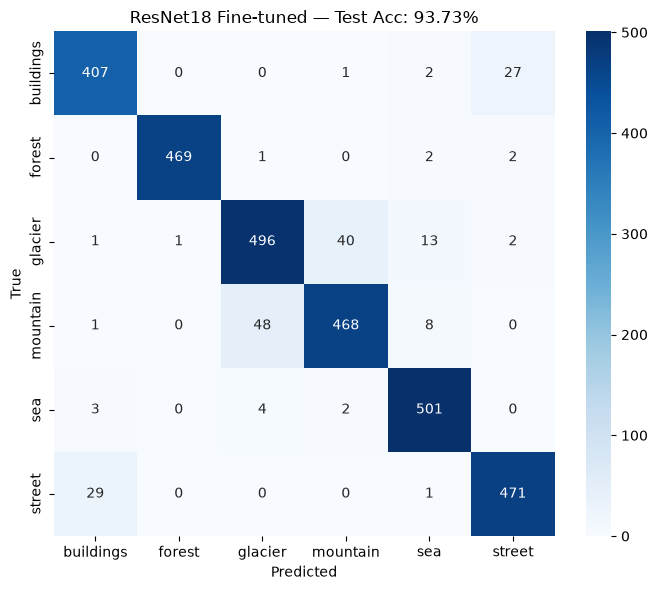

In [ ]:
# ===== ارزیابی نهایی: آماده‌سازی داده تست =====
test_dir = DATA_DIR / "seg_test" / "seg_test"

# fine-tuning (ImageNet stats)
eval_tf = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225]),
])

test_ds = datasets.ImageFolder(test_dir, transform=eval_tf)
test_loader = DataLoader(test_ds, batch_size=64, shuffle=False, num_workers=0)

CLASS_NAMES = test_ds.classes
print(f"Test samples : {len(test_ds)}")
print(f"Classes      : {CLASS_NAMES}")

# ===== بارگذاری بهترین چک‌پوینت =====
CKPT = PROJECT_ROOT / "models" / "best_resnet18_finetuned.pth" 
print("exists:", CKPT.exists())

eval_model = models.resnet18(weights=None)
eval_model.fc = nn.Linear(eval_model.fc.in_features, len(CLASS_NAMES))
eval_model.load_state_dict(torch.load(CKPT, map_location=DEVICE))
eval_model = eval_model.to(DEVICE).eval()
print("Model loaded.")

# ===== ارزیابی روی Test Set =====
from sklearn.metrics import classification_report, confusion_matrix

all_preds, all_labels = [], []
test_loss, correct = 0.0, 0

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs, labels = imgs.to(DEVICE), labels.to(DEVICE)
        outputs = eval_model(imgs)
        loss = criterion(outputs, labels)

        test_loss += loss.item() * imgs.size(0)
        preds = outputs.argmax(dim=1)
        correct += (preds == labels).sum().item()

        all_preds.append(preds.cpu().numpy())
        all_labels.append(labels.cpu().numpy())

all_preds  = np.concatenate(all_preds)
all_labels = np.concatenate(all_labels)

test_loss /= len(test_ds)
test_acc   = 100.0 * correct / len(test_ds)

print(f"Test Loss : {test_loss:.4f}")
print(f"Test Acc  : {test_acc:.2f}%\n")
print(classification_report(all_labels, all_preds,
                            target_names=CLASS_NAMES, digits=4))

import seaborn as sns

cm = confusion_matrix(all_labels, all_preds)

plt.figure(figsize=(7, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title(f"ResNet18 Fine-tuned — Test Acc: {test_acc:.2f}%")
plt.tight_layout()
plt.show()
